# RT-IoT2022 - Isolation Forest

Now we are going to apply the Isolation Forest to detect anomalous IoT traffic. The main steps are:

- load the preprocessed datasets
- train a baseline model with the default hyperparameters
- study the effect of contamination and n_estimators on the validation set
- evaluate the selected model once on the test set
- analyze which attacks are detected and which normal traffic causes false alarms

The Isolation Forest builds many random trees. Each tree splits the data with random cuts. Anomalies are "easy to isolate": they are separated from the rest of the data with only a few cuts. Normal samples need many more cuts. 

The model is trained only on normal traffic, and samples that are isolated too quickly are classified as anomalies (-1, converted to 1).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_val = pd.read_csv("../data/processed/X_val.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

train_metadata = pd.read_csv("../data/processed/train_metadata.csv")
val_metadata = pd.read_csv("../data/processed/val_metadata.csv")
test_metadata = pd.read_csv("../data/processed/test_metadata.csv")

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (7209, 92)
Validation set: (55356, 92)
Test set: (55357, 92)


In [3]:
y_val = (val_metadata["Label"] == "Anomaly").astype(int)
y_test = (test_metadata["Label"] == "Anomaly").astype(int)

print("Validation labels:")
print(y_val.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Validation labels:
Label
1    52953
0     2403
Name: count, dtype: int64

Test labels:
Label
1    52954
0     2403
Name: count, dtype: int64


### Baseline model

We first train the model with the default hyperparameters (`n_estimators=100`, `contamination=auto`) and evaluate it on the validation set.

In [4]:
baseline_model = IsolationForest(
    random_state = 42
)

baseline_model.fit(X_train)

IsolationForest(random_state=42)

In [5]:
baseline_predictions = baseline_model.predict(X_val)

baseline_predictions = (
    baseline_predictions == -1
).astype(int)

In [6]:
cm = confusion_matrix(y_val, baseline_predictions)
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

[[ 2183   220]
 [ 1366 51587]]

True Negatives: 2183
False Positives: 220
False Negatives: 1366
True Positives: 51587


In [7]:
accuracy = accuracy_score(y_val, baseline_predictions)
precision = precision_score(y_val, baseline_predictions)
recall = recall_score(y_val, baseline_predictions)
f1 = f1_score(y_val, baseline_predictions)

balanced_accuracy = balanced_accuracy_score(
    y_val,
    baseline_predictions
)

fpr = fp / (fp + tn)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("Balanced Accuracy:", balanced_accuracy)
print("False Positive Rate:", fpr)

Accuracy: 0.9713490859166125
Precision: 0.9957534696083541
Recall: 0.974203538987404
F1-score: 0.984860633829706
Balanced Accuracy: 0.9413256563018584
False Positive Rate: 0.09155222638368705


The baseline reaches a Balanced Accuracy of 0.941, with Recall 0.974, but the FPR is 0.092: about 9% of the normal traffic is flagged as an attack.

The default threshold is not adapted to our data, so we study the contamination parameter

In [8]:
baseline_scores = -baseline_model.decision_function(X_val)

roc_auc = roc_auc_score(
    y_val,
    baseline_scores
)

pr_auc = average_precision_score(
    y_val,
    baseline_scores
)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.9645524581629675
PR-AUC: 0.9951903021250628


## Hyperparameter analysis - contamination

contamination is the expected fraction of anomalies in the training data. The model uses it to set the threshold on the anomaly score: the most anomalous `contamination` % of the training samples are considered outliers.

Since our training set contains only normal traffic, this parameter directly controls the false alarms. 

For example, with contamination=0.05 about 5% of normal traffic will be flagged. 

In [9]:
contamination_values = [
    "auto",
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.10
]

In [10]:
contamination_results = []

for contamination in contamination_values:
    
    print("Testing contamination =", contamination)
    
    model = IsolationForest(
        n_estimators = 100,
        contamination = contamination,
        random_state = 42,
        n_jobs = 1
    )
    
    model.fit(X_train)
    
    predictions = model.predict(X_val)
    predictions = (predictions == -1).astype(int)
    
    cm = confusion_matrix(y_val, predictions)
    tn, fp, fn, tp = cm.ravel()
    
    precision = precision_score(y_val, predictions)
    recall = recall_score(y_val, predictions)
    f1 = f1_score(y_val, predictions)
    
    balanced_accuracy = balanced_accuracy_score(
        y_val,
        predictions
    )
    
    fpr = fp / (fp + tn)
    
    scores = -model.decision_function(X_val)
    
    roc_auc = roc_auc_score(y_val, scores)
    pr_auc = average_precision_score(y_val, scores)
    
    contamination_results.append({
        "contamination": contamination,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "balanced_accuracy": balanced_accuracy,
        "fpr": fpr,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    })

Testing contamination = auto
Testing contamination = 0.001
Testing contamination = 0.005
Testing contamination = 0.01
Testing contamination = 0.02
Testing contamination = 0.05
Testing contamination = 0.1


In [11]:
contamination_df = pd.DataFrame(
    contamination_results
)

contamination_df = contamination_df.sort_values(
    by = "balanced_accuracy",
    ascending = False
)

display(contamination_df)

best_contamination_result = contamination_df.iloc[0]

print(
    "Best contamination:",
    best_contamination_result["contamination"]
)

print(
    "Balanced Accuracy:",
    best_contamination_result["balanced_accuracy"]
)

print(
    "Recall:",
    best_contamination_result["recall"]
)

print(
    "False Positive Rate:",
    best_contamination_result["fpr"]
)

,contamination,precision,recall,f1,balanced_accuracy,fpr,roc_auc,pr_auc
5,0.05,0.997573,0.946802,0.971524,0.948016,0.050770,0.964552,0.99519
0,auto,0.995753,0.974204,0.984861,0.941326,0.091552,0.964552,0.99519
6,0.1,0.995394,0.975318,0.985253,0.937929,0.099459,0.964552,0.99519
1,0.001,0.875000,0.000264,0.000529,0.499716,0.000832,0.964552,0.99519
2,0.005,0.910714,0.001926,0.003844,0.498882,0.004161,0.964552,0.99519
4,0.02,0.938289,0.012634,0.024932,0.497162,0.018310,0.964552,0.99519
3,0.01,0.918367,0.005949,0.011821,0.497148,0.011652,0.964552,0.99519


Best contamination: 0.05
Balanced Accuracy: 0.9480160049593362
Recall: 0.9468018809132627
False Positive Rate: 0.05076987099459009


The best value of contamination is 0.05, with a validation Balanced Accuracy of 0.948 (Recall 0.947, False Positive Rate 0.051). As expected, the False Positive Rate is very close to the contamination value.

We can also see that with values from 0.001 to 0.02 the model detects almost no attacks (Recall close to 0), while with 0.05 the Recall jumps to about 0.95. 

This means that many attacks (mostly DOS_SYN_Hping) receive an anomaly score similar to the most unusual normal flows and the threshold must be low enough to include them. So the Isolation Forest is very sensitive to the choice of the threshold.

With contamination=0.10 the Recall increases slightly, but the false alarms double (about 10%).

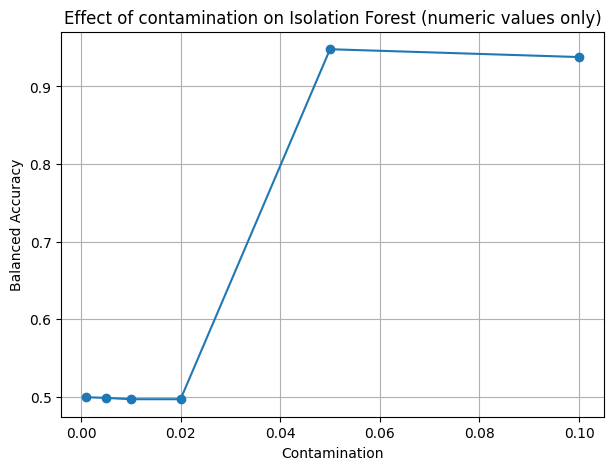

In [12]:
numeric_contamination = contamination_df[
    contamination_df["contamination"] != "auto"
].copy()

numeric_contamination["contamination"] = (
    numeric_contamination["contamination"].astype(float)
)

numeric_contamination = numeric_contamination.sort_values(
    "contamination"
)

plt.figure(figsize=(7,5))

plt.plot(
    numeric_contamination["contamination"],
    numeric_contamination["balanced_accuracy"],
    marker="o"
)

plt.xlabel("Contamination")
plt.ylabel("Balanced Accuracy")
plt.title("Effect of contamination on Isolation Forest (numeric values only)")
plt.grid()

plt.show()

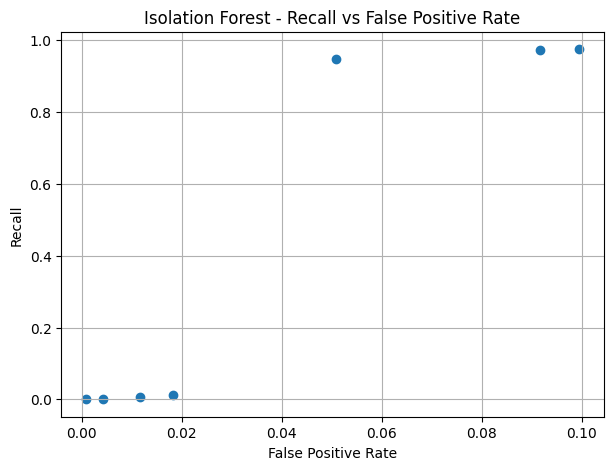

In [13]:
plt.figure(figsize=(7,5))

plt.scatter(
    contamination_df["fpr"],
    contamination_df["recall"]
)

plt.xlabel("False Positive Rate")
plt.ylabel("Recall")
plt.title("Isolation Forest - Recall vs False Positive Rate")
plt.grid()

plt.show()

The plot shows the trade-off between detected attacks and false alarms for the different contamination values.

## Hyperparameter analysis - n_estimators

n_estimators is the number of trees; more trees give a more stable anomaly score but require more computation.

In [14]:
n_estimators_values = [50, 100, 200, 300]

best_contamination = contamination_df.iloc[0][
    "contamination"
]

print(
    "Selected contamination:",
    best_contamination
)

Selected contamination: 0.05


In [15]:
estimators_results = []

for n_estimators in n_estimators_values:
    
    print(
        "Testing n_estimators =",
        n_estimators
    )

    model = IsolationForest(
       n_estimators = n_estimators,
       contamination = best_contamination,
       random_state = 42,
       n_jobs = -1
    )

    model.fit(X_train)

    predictions = model.predict(X_val)
    predictions = (predictions == -1).astype(int)   

    cm = confusion_matrix(y_val, predictions) 
    tn, fp, fn, tp = cm.ravel()

    precision = precision_score(
      y_val,
      predictions
    )

    recall = recall_score(
      y_val,
      predictions
    )

    f1 = f1_score(
      y_val,
      predictions 
    )

    balanced_accuracy = balanced_accuracy_score(
      y_val,
      predictions
    )

    fpr = fp / (fp + tn)

    scores = -model.decision_function(X_val)

    roc_auc = roc_auc_score(
      y_val,
      scores
    )

    pr_auc = average_precision_score(
      y_val, 
      scores
    )

    estimators_results.append({
      "n_estimators": n_estimators,
      "balanced_accuracy": balanced_accuracy,
      "precision": precision,
      "recall": recall,
      "f1": f1,
      "fpr": fpr,
      "roc_auc": roc_auc,
      "pr_auc": pr_auc
    })

Testing n_estimators = 50
Testing n_estimators = 100
Testing n_estimators = 200
Testing n_estimators = 300


In [16]:
estimators_df = pd.DataFrame(
    estimators_results
)

estimators_df = estimators_df.sort_values(
    by = "balanced_accuracy",
    ascending = False
)

display(estimators_df)

best_estimators = int(
    estimators_df.iloc[0]["n_estimators"]
)

print(
    "Selected n_estimators:",
    best_estimators
)

,n_estimators,balanced_accuracy,precision,recall,f1,fpr,roc_auc,pr_auc
1,100,0.948016,0.997573,0.946802,0.971524,0.050770,0.964552,0.995190
3,300,0.942116,0.997618,0.933337,0.964408,0.049105,0.965324,0.995291
0,50,0.940352,0.997686,0.928144,0.961659,0.047441,0.968493,0.995736
2,200,0.936696,0.997571,0.922913,0.958791,0.049521,0.964263,0.995435


Selected n_estimators: 100


The differences between the values are small (Balanced Accuracy between about 0.936 and 0.948) and they do not follow a clear trend: more trees do not improve the results. 

We select n_estimators = 100, which gives the best Balanced Accuracy and is also the fastest among the best options.

### Final model and test evaluation

The final model uses `contamination=0.05` and `n_estimators=100`. Again, the test set is used only here, once.

In [17]:
final_model = IsolationForest(
    n_estimators = best_estimators,
    contamination = best_contamination,
    random_state = 42,
    n_jobs = -1
)

final_model.fit(X_train)

IsolationForest(contamination=0.05, n_jobs=-1, random_state=42)

In [18]:
test_predictions = final_model.predict(X_test)

test_predictions = (
    test_predictions == -1
).astype(int)

test_cm = confusion_matrix(
    y_test,
    test_predictions
)

tn, fp, fn, tp = test_cm.ravel()

print("Confusion Matrix:")
print(test_cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


Confusion Matrix:
[[ 2275   128]
 [ 2739 50215]]

True Negatives: 2275
False Positives: 128
False Negatives: 2739
True Positives: 50215


In [19]:
test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_precision = precision_score(
    y_test,
    test_predictions
)

test_recall = recall_score(
    y_test,
    test_predictions
)

test_f1 = f1_score(
    y_test,
    test_predictions
)

test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_predictions
)

test_fpr = fp / (fp + tn)

test_scores = -final_model.decision_function(
    X_test
)

test_roc_auc = roc_auc_score(
    y_test,
    test_scores
)

test_pr_auc = average_precision_score(
    y_test,
    test_scores
)    

print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Recall:", test_recall)
print("F1-score:", test_f1)
print("Balanced Accuracy:", test_balanced_accuracy)
print("False Positive Rate:", test_fpr)
print("ROC-AUC:", test_roc_auc)
print("PR-AUC:", test_pr_auc)

Accuracy: 0.9482088986036094
Precision: 0.9974574419482352
Recall: 0.9482758620689655
F1-score: 0.9722450797215795
Balanced Accuracy: 0.9475045560865011
False Positive Rate: 0.05326674989596338
ROC-AUC: 0.9593723419619798
PR-AUC: 0.9946439919558508


On the test set the model reaches a Balanced Accuracy of 0.948, Recall 0.948 and False Positive Rate 0.053. The results are consistent with the validation set.

Compared with the One-Class SVM, the Isolation Forest produces a similar number of false alarms but misses many more attacks (2,739 against 518).

In [20]:
attack_analysis = test_metadata.copy()

attack_analysis["Prediction"] = test_predictions

attack_analysis = attack_analysis[
    attack_analysis["Label"] == "Anomaly"
]

attack_detection = attack_analysis.groupby(
    "Attack_type"   
)["Prediction"].agg(["count", "sum"])

attack_detection["detection_rate"] = (
    attack_detection["sum"] /
    attack_detection["count"]
)

attack_detection

,count,sum,detection_rate
Attack_type,,,
ARP_poisioning,3813,1756,0.460530
DDOS_Slowloris,266,183,0.687970
DOS_SYN_Hping,45045,44465,0.987124
Metasploit_Brute_Force_SSH,18,15,0.833333
NMAP_FIN_SCAN,14,12,0.857143
NMAP_OS_DETECTION,1000,1000,1.000000
NMAP_TCP_scan,501,499,0.996008
NMAP_UDP_SCAN,1292,1281,0.991486
NMAP_XMAS_TREE_SCAN,1005,1004,0.999005


The model detects correctly almost all the attacks but in particular it struggles with two of them:

- **ARP_poisoning** 
- **DDOS_Slowloris** (Slowloris keeps connections open and sends data very slowly, so its flows can look similar to normal long connections.)

These two attacks explain most of the difference with the other models.

In [21]:
normal_analysis = test_metadata.copy()
normal_analysis["Prediction"] = test_predictions
normal_analysis = normal_analysis[normal_analysis["Label"] == "Normal"]

false_alarms = normal_analysis.groupby("Attack_type")["Prediction"].agg(["count", "sum"])
false_alarms.columns = ["normal_samples", "false_alarms"]

false_alarms["false_positive_rate"] = (
    false_alarms["false_alarms"] / false_alarms["normal_samples"]
)

false_alarms

,normal_samples,false_alarms,false_positive_rate
Attack_type,,,
MQTT_Publish,829,8,0.009650
Thing_Speak,1530,81,0.052941
Wipro_bulb,44,39,0.886364


The false alarms on MQTT_Publish (1.0%) and Thing_Speak (5.3%) are low but in the last one we can see 39 of the 44 Wipro_bulb samples (89%) are flagged as attacks.

This is the worst result among the three models for this device, which has very few training samples.

In [22]:
contamination_df.to_csv(
    "../results/tables/isolation_forest_contamination.csv",
    index = False 
)

estimators_df.to_csv(
    "../results/tables/isolation_forest_estimators_results.csv",
    index = False
)

attack_detection.to_csv(
    "../results/tables/isolation_forest_attack_detection.csv",
)

In [23]:
tn, fp, fn, tp = test_cm.ravel()

final_metrics = pd.DataFrame([{
    "model": "Isolation Forest",
    "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    "accuracy": test_accuracy,
    "precision": test_precision,
    "recall": test_recall,
    "f1": test_f1,
    "balanced_accuracy": test_balanced_accuracy,
    "fpr": test_fpr,
    "roc_auc": test_roc_auc,
    "pr_auc": test_pr_auc
}])

final_metrics.to_csv("../results/tables/isolation_forest_final_metrics.csv", index=False)
false_alarms.to_csv("../results/tables/isolation_forest_false_alarms.csv")
final_metrics

,model,tn,fp,fn,tp,accuracy,precision,recall,f1,balanced_accuracy,fpr,roc_auc,pr_auc
0,Isolation Forest,2275,128,2739,50215,0.948209,0.997457,0.948276,0.972245,0.947505,0.053267,0.959372,0.994644


## Conclusions

- With the default `contamination="auto"` the model produces about 9% false alarms.
- `contamination=0.05` gives the best balance. Smaller values make the model miss almost all attacks, so the Isolation Forest is very sensitive to the threshold.
- The number of trees has little effect; we keep 100.
- On the test set: Balanced Accuracy 0.948, Recall 0.948, False Positive Rate 0.053.
- Weak points: ARP_poisoning (46%) and DDOS_Slowloris (69%) among the attacks, and Wipro_bulb (89% false alarms) among the normal devices.